<a id="summary"></a>

# Native backbone: OPERA thắng ở đâu, mất gì, và khác gì so với backbone qua QuITE?

> **Dữ liệu:** gói tổng kết 15/11/2026 (`results/bao_cao/2026-11-15/`): 8 setting forecasting × 11 backbone × {Vanilla, OPERA} × 5 seed = 694 run. Gồm **6 native** (GRU-D, mTAND, Warpformer, và mới thêm **t-PatchGNN, GraFITi, CRU**) và **5 non-native qua QuITE** (iTransformer, PatchTST, TMix, và mới thêm **DLinear, SegRNN**). 240 run GRU-D/mTAND/Warpformer giống hệt bản 11/11. *Bản trước (chỉ 3 native backbone) nằm ở `analysis/_ban_cu/02_native_backbone_analysis_truoc_15_11_20261115.ipynb`. Severity sweep: [03_tong_ket.ipynb](03_tong_ket.ipynb).*
>
> **Trả lời ngắn:** Khi bị xóa bớt lần đo, OPERA thắng ở **cả 6 native backbone** (755/800 cặp seed, 39/40 ô dataset × backbone thắng ≥ 75% số cặp). Khi clean, native **gần như hòa** (+0.8% trung bình, 125/200 cặp; 33/40 ô trong ±2.5%), còn **non-native thì kém đi** (27/29 ô thua, trung vị −4.1%, 17/145 cặp). Ranh giới nằm ở **nhóm backbone**: Vanilla non-native sụp ×5–8 khi shift, native chỉ +40–140%. Mức sụp đó *không* dự báo chi phí clean bên trong nhóm native (Spearman +0.02), nhưng có trong nhóm non-native (−0.67). Ba backbone native mới lặp lại đúng kết luận của GRU-D/mTAND/Warpformer; hai ngoại lệ clean là CRU · Activity (−4.1%, 0/5) và t-PatchGNN · USHCN (−4.2%, chủ yếu do 1 seed).

| Phần | # | Kết luận | Bằng chứng | Xem hình |
|---|---|---|---|---|
| §1 | 1 | Shift: OPERA thắng ở **mọi backbone**, cả native lẫn non-native | Native 755/800 cặp, non-native 566/580. Trung vị theo ô: native +22%, non-native +67%. Ô yếu nhất: USHCN · CRU +0.2% (14/20), USHCN · Warpformer +1.1% (15/20) | [Hình 1.1b](#hinh-1-1), [Bảng 1.2](#bang-1-2) |
| §1 | 2 | Clean: **hai nhóm khác hẳn nhau**. Native gần hòa, non-native kém đi | Native: trung vị theo backbone −2.2% (CRU) đến +1.6%, 125/200 cặp. Non-native: −2.5% đến −6.3%, mỗi backbone thắng nhiều nhất 1 dataset | [Hình 1.1a](#hinh-1-1), [Bảng 1.2](#bang-1-2) |
| §2 | 3 | Ba native mới (t-PatchGNN, GraFITi, CRU) **giống ba native cũ** | Shift: t-PatchGNN 133/140, GraFITi 138/140, CRU 32/40. Clean GraFITi thắng 7/7 dataset (26/35 cặp); t-PatchGNN 5/7 | [Bảng 2.1](#bang-2-1) |
| §3 | 4 | Mức thắng khi shift **do dataset quyết định**: NOAA > VitalDB > Activity > CGMacros ≈ PhysioNet 36h > PhysioNet 12h > USHCN | Gộp native: NOAA +45.3% (3 bb), VitalDB +38.7, Activity 2s +34.2 / 1s +32.5, CGMacros +17.4, PhysioNet 36h +16.9 / 12h +10.9, USHCN +6.4 | [Hình 3.1](#hinh-3-1), [Bảng 3.3](#bang-3-3) |
| §3 | 5 | Thứ tự đó trùng với **mức Vanilla sụp**, và Vanilla native sụp chủ yếu khi **mất biến** | Spearman 0.95 trên 160 điểm. Vanilla tụt khi variables: NOAA ×19, Activity 2s ×6.8, VitalDB ×5.6; timing chỉ +7% đến +32% | [Hình 3.1b](#hinh-3-1), [Hình 3.2a](#hinh-3-2) |
| §3 | 6 | OPERA **giảm** mức tụt chứ không xóa hết | MSE shift ÷ clean của OPERA: trung vị 1.19; tối đa ×4.5 (NOAA · GRU-D · variables, Vanilla ×27) | [Hình 3.2b](#hinh-3-2) |
| §4 | 7 | Chi phí clean **đi theo nhóm backbone**, không theo mức nhạy bên trong nhóm native | Spearman (Vanilla tụt khi shift, clean OPERA hơn): gộp −0.55; native +0.02 (p = 0.92); non-native −0.67 (p = 6e-5) | [Hình 4.1](#hinh-4-1) |
| §4 | 8 | Ô clean thua nặng đều là **non-native**, nhiều ô là model yếu sẵn | 13/29 ô non-native kém ≥ 5%, native 0/40. NOAA: PatchTST −25.1%, TMix −18.8%, iTransformer −17.0%, với MSE Vanilla đã gấp ~3 lần GRU-D (0.0022 so với 0.0007) | [Bảng 4.2](#bang-4-2) |
| §5 | 9 | Phần thắng clean của **Warpformer** không chắc chắn (run Vanilla NaN) | Bỏ seed NaN: NOAA +5.3% → +0.9%; Activity 2s +0.4% → −6.9% (0/3). Shift không đổi | [Bảng 5.1](#bang-5-1) |
| §5 | 10 | Hai ô native thua clean: **CRU · Activity** là thua thật; **t-PatchGNN · USHCN** chủ yếu do seed | CRU · Activity: cả 5 seed thua (−2.8% đến −6.7%). t-PatchGNN · USHCN: seed 0 −14.1%, các seed còn lại −5.9% đến +0.2% | [Bảng 5.2](#bang-5-2) |
| §5 | 11 | Xu hướng giống các run irregular cũ trong `results/` (không ghép cặp được) | Cũ: Activity +39.0%, USHCN 12 tháng −1.0% khi shift; mới: Activity +36.5%, USHCN 6 tháng +7.1% | [Bảng 5.3](#bang-5-3) |

**Kết luận.** OPERA bền với việc xóa bớt lần đo trên cả 11 backbone và 8 dataset. Độ lớn lợi ích do dataset quyết định (mất một biến thì mất bao nhiêu thông tin). **Chi phí trên clean** thì do nhóm backbone quyết định: với native backbone gần như bằng 0, với backbone qua QuITE thì khoảng 2–6% (tới 25% ở NOAA). Khi viết paper: (i) tách hai nhóm khi báo kết quả clean, không gộp; (ii) không trích Spearman 0.55 gộp làm bằng chứng "nhạy càng nhiều thì càng mất clean", vì bên trong nhóm native không có quan hệ đó; (iii) báo kèm MSE tuyệt đối, vì nhiều ô thua nặng là backbone non-native vốn đã yếu hơn native ở cùng dataset.

**Lưu ý về con số.** "OPERA hơn (%)" ở đây = trung bình các cặp (seed [× loại shift]) của (Vanilla − OPERA) / Vanilla, **dương = OPERA tốt hơn**. `TONG_KET.md` / `BANG_SO_LIEU.md` lấy MSE trung bình rồi mới so, và **âm = OPERA tốt hơn**, nên số ở đó khác (ví dụ NOAA · GRU-D shift −77.0% ở đó, +50.3% ở đây). Cả hai đều đúng, chỉ cần ghi rõ dùng kiểu nào.

**Giả thuyết chưa kiểm chứng.** (a) Student của OPERA không bao giờ thấy view sạch (`train_processes` trong `config.yaml` không có `identity`). Với native backbone, view thưa vẫn là "cùng loại input" nên không sao; với QuITE, token thay đổi mạnh khi xóa bớt điểm (Vanilla non-native tụt ×4.6 ngay cả với timing, native chỉ +10%), nên model chuyên cho dữ liệu thưa và kém đi trên clean. `TONG_KET.md` mục 4 đề xuất thêm `identity` vào pool rồi chạy lại SegRNN/DLinear trên VitalDB để kiểm. (b) iTransformer/PatchTST/TMix chạy ở commit cũ hơn (`ce9a1cc`, `062d811`) so với mọi backbone khác (`e606587`). DLinear/SegRNN cùng commit với native mà vẫn thua clean, nên khác biệt commit có lẽ không phải nguyên nhân chính. (c) Native backbone là **bản tự cài lại** theo mô tả trong paper gốc, dùng hyper-parameter chung (docstring `irregular_baselines.py`), nên MSE tuyệt đối không so được với bảng của paper gốc.

**Bước tiếp theo đề xuất:** câu hỏi về dataset: *"Vì sao NOAA làm backbone qua QuITE kém đi 17–25% trên clean, còn native trên NOAA thì không?"* So phân phối quan sát của NOAA (mật độ, số điểm mỗi patch) với các dataset khác để xem token QuITE ở NOAA có thay đổi đặc biệt mạnh khi xóa bớt điểm hay không.

*Nguồn số liệu:* `results/bao_cao/2026-11-15/per_run.csv` (cột `mse[...]`, `family`, `nan_during_training`) và `results/runs/*/results.json` (`cost.epochs_run`, `best.epoch`, `run.git_commit`, `info`). Ghép cặp theo seed; cặp thiếu một phía bị bỏ (VitalDB · CRU chỉ có 4 run Vanilla). So sánh cũ: `results/cu_ce9a1cc/per_seed_results.csv` (group `irregular_backbone`, task `forecast`).

<a id="phan-1"></a>

# 1. Toàn cảnh: 11 backbone

[↑ Tóm tắt](#summary)

<a id="hinh-1-1"></a>

#### 📈 Hình 1.1 · Thắng/thua của OPERA theo dataset × backbone

- **Hàng:** 8 setting. **Cột:** 6 native backbone (trái vạch đen) và 5 non-native qua QuITE (phải). Ô xám = chưa chạy. ⚠ = có run Vanilla bị NaN khi train ([Bảng 5.1](#bang-5-1)).
- **Mỗi ô:** dòng trên = % OPERA hơn Vanilla (trung bình các cặp, dương = tốt hơn); dòng dưới = số cặp OPERA thắng.

In [1]:
from pathlib import Path
import json, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'results' / 'README.md').exists())
PKG = ROOT / 'results' / 'bao_cao' / '2026-11-15'   # per_run.csv của gói 15/11
OUT = ROOT / 'analysis' / 'figures'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 250, 'display.max_columns', 30)

def save(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(OUT / f'{name}.png')))

def mark(w, n):
    return '🟢' if w >= 0.8 * n else ('🔴' if w <= 0.2 * n else '⚪')

DS = ['noaa_isd', 'vitaldb', 'activity_h1000', 'activity_h2000', 'cgmacros', 'physionet_h12', 'physionet_h36', 'ushcn_6mo']
NAME = {'noaa_isd': 'NOAA ISD 24h→6h', 'vitaldb': 'VitalDB 60→15min', 'activity_h1000': 'Activity 1s→3s',
        'activity_h2000': 'Activity 2s→2s', 'cgmacros': 'CGMacros 180→60min', 'physionet_h12': 'PhysioNet 12h→36h',
        'physionet_h36': 'PhysioNet 36h→12h', 'ushcn_6mo': 'USHCN 24→6 tháng'}
NATIVE = {'grud': 'GRU-D', 'mtand': 'mTAND', 'warpformer': 'Warpformer', 'tpatchgnn': 't-PatchGNN', 'grafiti': 'GraFITi', 'cru': 'CRU'}
NONNAT = {'itransformer': 'iTransformer', 'patchtst': 'PatchTST', 'tmix': 'TMix', 'dlinear': 'DLinear', 'segrnn': 'SegRNN'}
BB = {**NATIVE, **NONNAT}
COND = {'random_dropout:0.7': 'density', 'temporal_stride:3': 'timing', 'variable_dropout:0.5': 'variables',
        'temporal_stride:3+variable_group_dropout:0.3': 'composed'}

# 1 dòng = 1 run. Thêm epoch / best epoch / commit / thông tin task từ results.json.
runs = pd.read_csv(PKG / 'per_run.csv')
meta = []
for f in sorted((ROOT / 'results' / 'runs').glob('*/results.json')):
    r = json.loads(f.read_text())
    m = re.match(r'bench_(.+)_([a-z]+)_(opera|vanilla)_s(\d)$', f.parent.name)
    meta.append({'dataset': m[1], 'backbone': m[2], 'method': m[3], 'seed': int(m[4]),
                 'epochs_run': r['cost']['epochs_run'], 'best_epoch': r['best']['epoch'], 'params': r['cost']['n_params'],
                 'commit': r['run']['git_commit'][:7], 'n_test': r['per_condition']['identity']['n_series'],
                 'history': r['info']['history'], 'pred_window': r['info']['pred_window'], 'n_vars': r['info']['input_dim'],
                 'n_train_batches': r['info']['n_train_batches'], 'batch_size': r['info']['batch_size']})
runs = runs.merge(pd.DataFrame(meta), on=['dataset', 'backbone', 'method', 'seed'])
runs['clean_mse'] = runs['mse[identity]']
long = runs.melt(id_vars=['dataset', 'backbone', 'family', 'method', 'seed', 'nan_during_training'],
                 value_vars=[f'mse[{c}]' for c in ['identity', *COND]], var_name='condition', value_name='mse')
long['condition'] = long.condition.str[4:-1]

# Ghép cặp theo seed: "OPERA hơn (%)" = (Vanilla − OPERA) / Vanilla, dương = OPERA tốt hơn. Cặp thiếu một phía bị bỏ.
pa = long.pivot_table(index=['dataset', 'backbone', 'family', 'seed', 'condition'], columns='method', values='mse').dropna().reset_index()
clean = pa[pa.condition.eq('identity')].set_index(['dataset', 'backbone', 'seed'])[['vanilla', 'opera']]
pa = pa.join(clean.add_suffix('_clean'), on=['dataset', 'backbone', 'seed'])
pa['gain'] = 100 * (pa.vanilla - pa.opera) / pa.vanilla
pa['win'] = pa.opera < pa.vanilla
pa['part'] = np.where(pa.condition.eq('identity'), 'clean', 'shift')
pa['vanilla_delta'] = 100 * (pa.vanilla / pa.vanilla_clean - 1)   # Vanilla tụt bao nhiêu % so với clean của chính nó
pa['opera_delta'] = 100 * (pa.opera / pa.opera_clean - 1)
pn = pa[pa.family.eq('native')]                                     # chỉ native backbone (§2–§3)
nanrun = runs[runs.nan_during_training.eq(1)][['dataset', 'backbone', 'method', 'seed']]
lone = runs.groupby(['dataset', 'backbone']).method.nunique().loc[lambda s: s < 2]
print(f'{len(runs)} run · {runs.dataset.nunique()} dataset · {runs.backbone.nunique()} backbone')
print('Commit theo backbone:', runs.groupby('commit').backbone.unique().map(sorted).to_dict())
print('Run bị NaN khi train:', ', '.join(f'{r.dataset}/{r.backbone}/{r.method}/s{r.seed}' for r in nanrun.itertuples()))
print('Có run nhưng thiếu một phía (không tính):', list(lone.index))


694 run · 8 dataset · 11 backbone
Commit theo backbone: {'062d811': ['itransformer', 'patchtst', 'tmix'], 'ce9a1cc': ['itransformer', 'patchtst', 'tmix'], 'e606587': ['cru', 'dlinear', 'grafiti', 'grud', 'mtand', 'segrnn', 'tpatchgnn', 'warpformer']}
Run bị NaN khi train: activity_h2000/warpformer/vanilla/s0, activity_h2000/warpformer/vanilla/s2, noaa_isd/warpformer/vanilla/s4
Có run nhưng thiếu một phía (không tính): [('vitaldb', 'cru')]


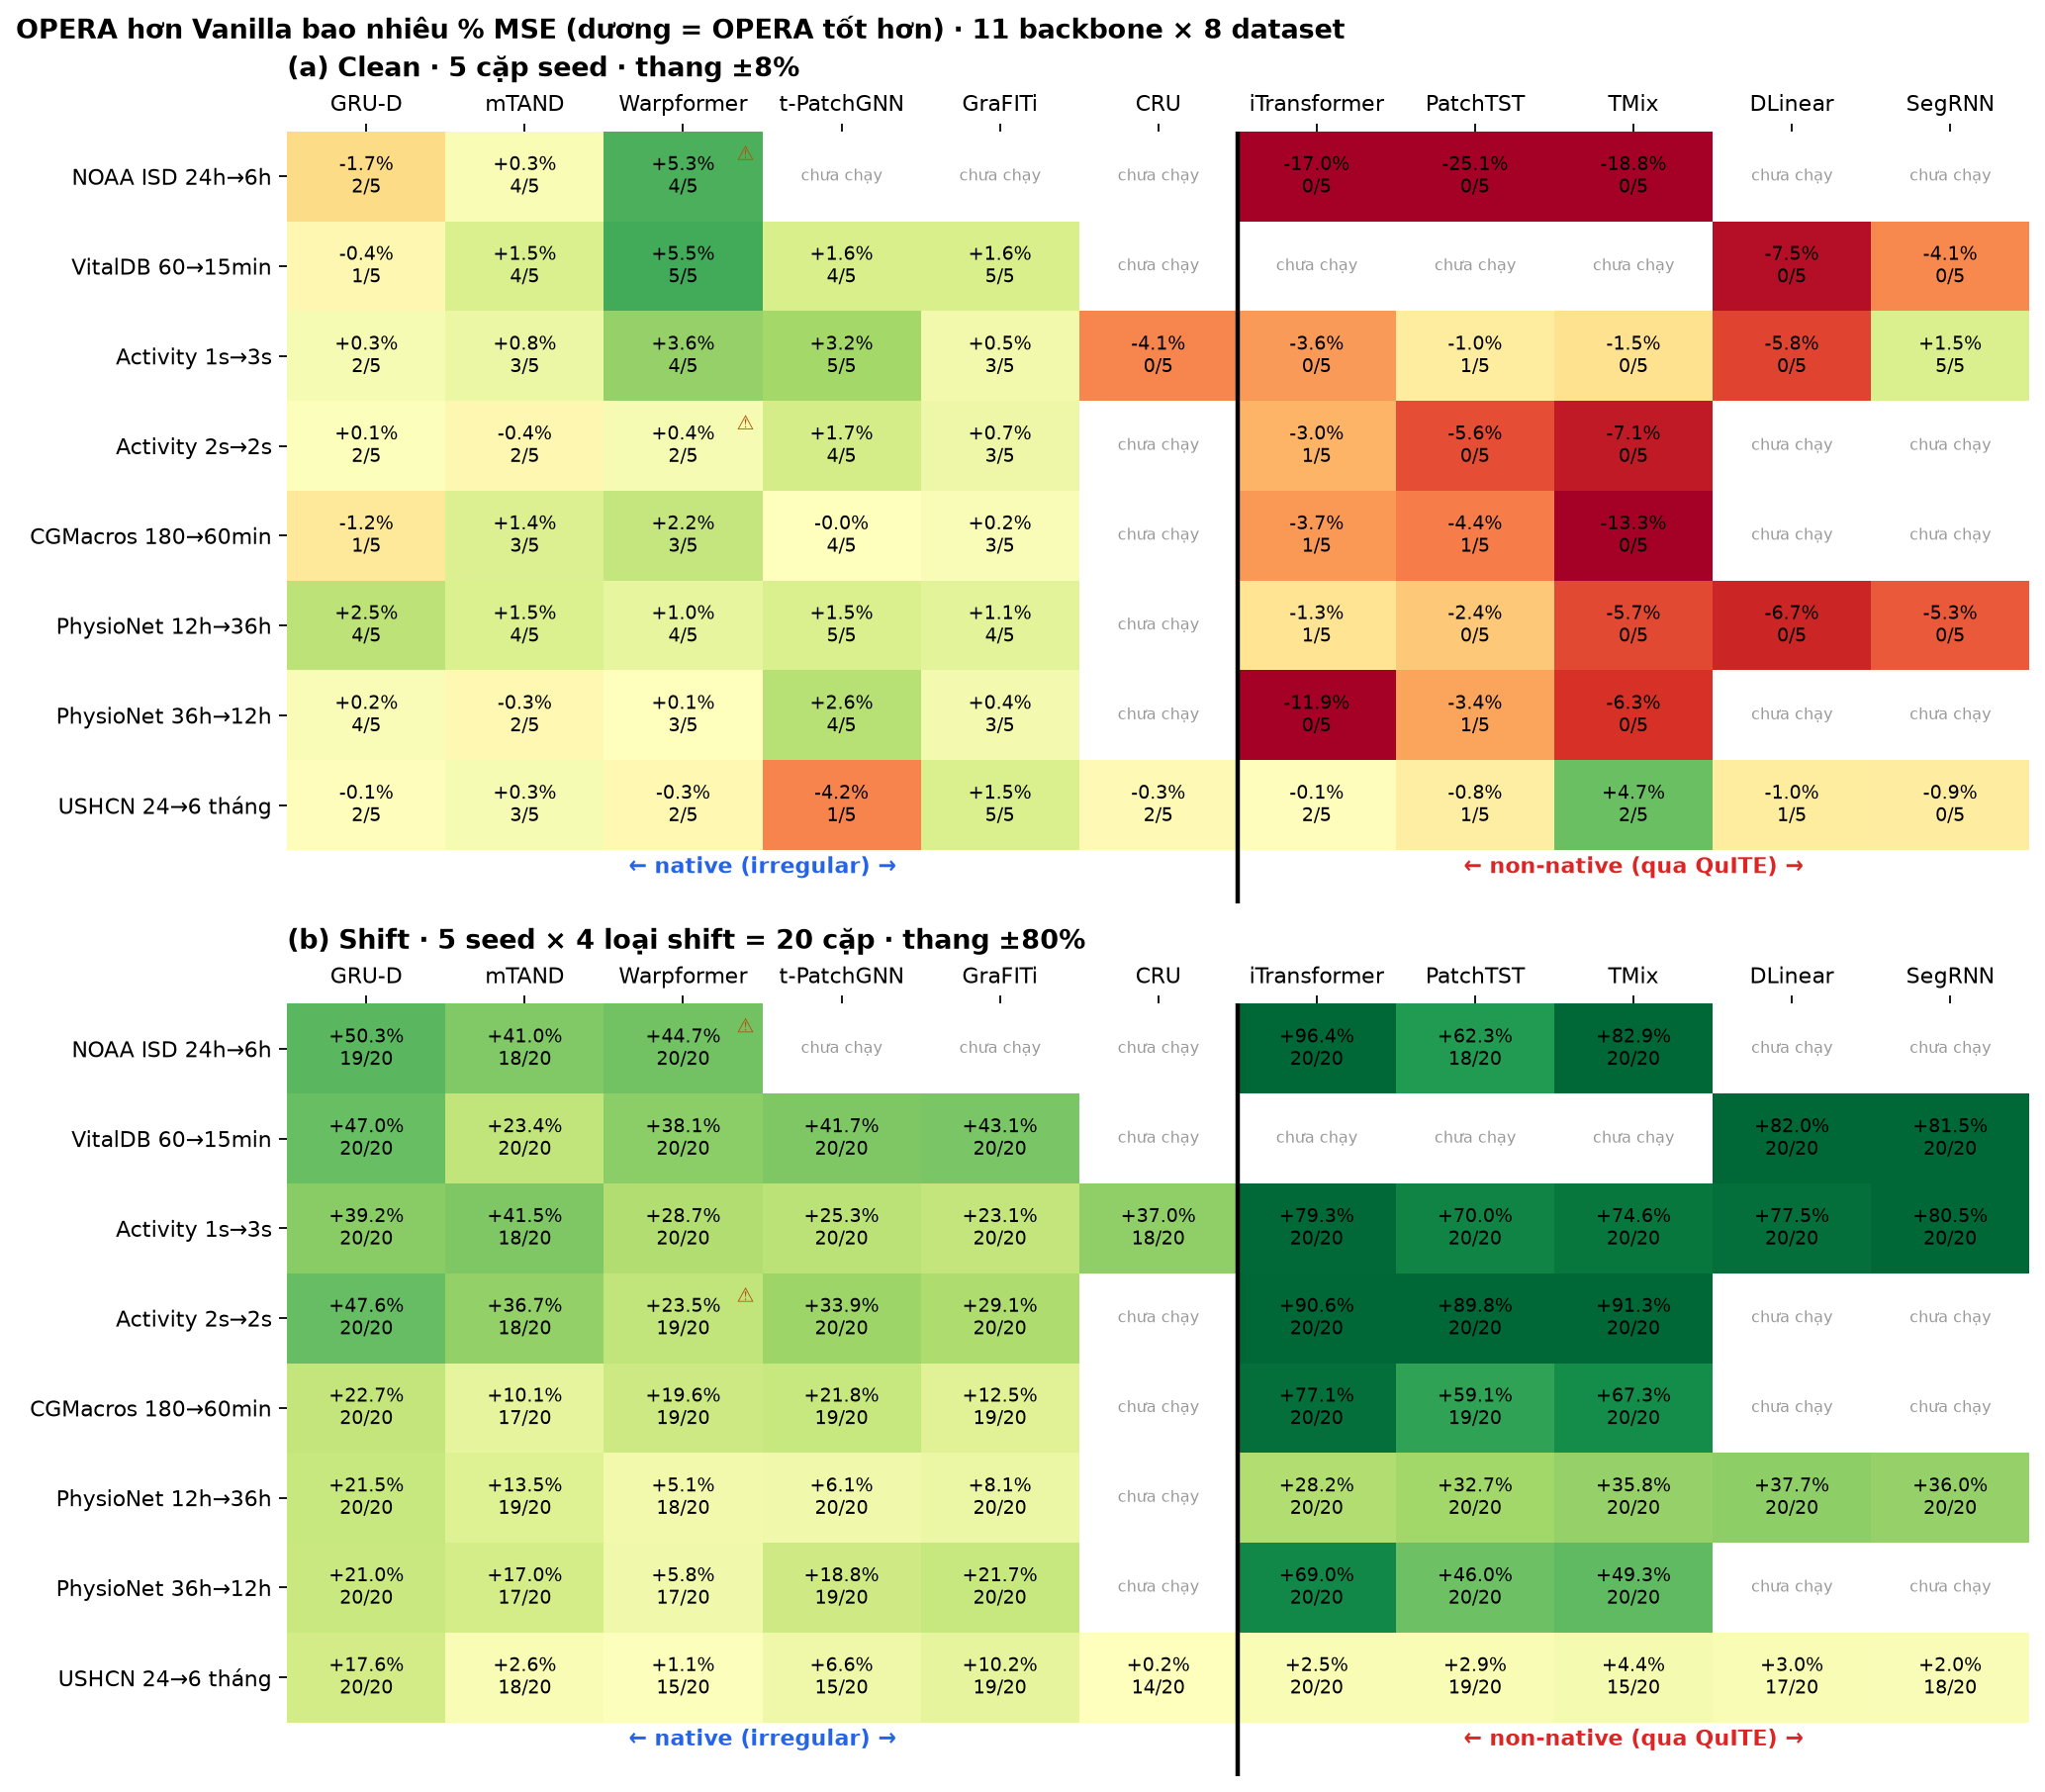

In [2]:
# Toàn cảnh: % OPERA hơn Vanilla ở mỗi ô dataset × backbone (trung bình các cặp seed [× loại shift]).
cell = pa.groupby(['part', 'dataset', 'backbone']).agg(gain=('gain', 'mean'), w=('win', 'sum'), n=('win', 'size')).reset_index()
cols = list(BB)
fig, axes = plt.subplots(2, 1, figsize=(13, 11.5))
for ax, part, lim in zip(axes, ['clean', 'shift'], [8, 80]):
    d = cell[cell.part.eq(part)].set_index(['dataset', 'backbone'])
    G = d.gain.unstack().reindex(index=DS, columns=cols)
    ax.imshow(np.ma.masked_invalid(G.values), cmap='RdYlGn', vmin=-lim, vmax=lim, aspect='auto')
    for i, s in enumerate(DS):
        for j, b in enumerate(cols):
            if (s, b) in d.index:
                r = d.loc[(s, b)]
                ax.text(j, i, f'{r.gain:+.1f}%\n{r.w}/{r.n}', ha='center', va='center', fontsize=8.5)
            else:
                ax.text(j, i, 'chưa chạy', ha='center', va='center', fontsize=7, color='#999')
    for _, r in nanrun.drop_duplicates(['dataset', 'backbone']).iterrows():
        ax.text(cols.index(r.backbone) + .45, DS.index(r.dataset) - .35, '⚠', ha='right', va='top', fontsize=9, color='#b45309')
    ax.axvline(len(NATIVE) - .5, color='black', lw=2)
    ax.set_xticks(range(len(cols)), BB.values()); ax.set_yticks(range(len(DS)), [NAME[s] for s in DS])
    ax.xaxis.tick_top()
    ax.text(len(NATIVE) / 2 - .5, len(DS) - .43, '← native (irregular) →', ha='center', va='top', fontweight='bold', color='#2563eb')
    ax.text(len(NATIVE) + len(NONNAT) / 2 - .5, len(DS) - .43, '← non-native (qua QuITE) →', ha='center', va='top', fontweight='bold', color='#dc2626')
    ax.set_ylim(len(DS) + .1, -.5)
    ax.set_title({'clean': '(a) Clean · 5 cặp seed · thang ±8%', 'shift': '(b) Shift · 5 seed × 4 loại shift = 20 cặp · thang ±80%'}[part],
                 loc='left', fontweight='bold', pad=8)
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle('OPERA hơn Vanilla bao nhiêu % MSE (dương = OPERA tốt hơn) · 11 backbone × 8 dataset', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save(fig, 'native_fig1_1_win_map_11bb')


**Kết luận:** (b) xanh ở mọi ô có chạy. Cột non-native đậm hơn hẳn (+60 đến +96%) vì Vanilla của chúng sụp nặng hơn. (a) hai nửa khác hẳn nhau: bên native gần như vàng (hòa), lác đác xanh nhạt; bên non-native gần như toàn cam/đỏ, đậm nhất ở hàng NOAA. Hai ô cam bên native là CRU · Activity và t-PatchGNN · USHCN ([Bảng 5.2](#bang-5-2)).

<a id="bang-1-2"></a>

#### 📋 Bảng 1.2 · Gộp theo backbone

- Mỗi dataset cho 1 giá trị (trung bình các cặp), rồi lấy **trung vị qua các dataset**. "Cặp thắng" cộng mọi cặp seed (clean) hoặc seed × loại shift (shift).
- **Vanilla tụt khi shift:** MSE shift ÷ MSE clean của chính Vanilla − 1 (trung vị qua dataset). **commit:** commit code của các run.

In [3]:
# Gộp theo backbone: mỗi dataset 1 giá trị (trung bình các cặp), rồi lấy trung vị qua các dataset.
cd = pa.groupby(['family', 'backbone', 'dataset', 'part']).agg(gain=('gain', 'mean'), w=('win', 'sum'), n=('win', 'size'),
                                                              vd=('vanilla_delta', 'mean')).reset_index()
rows = []
for b in BB:
    c, x = cd[cd.backbone.eq(b) & cd.part.eq('clean')], cd[cd.backbone.eq(b) & cd.part.eq('shift')]
    xs = pa[pa.backbone.eq(b) & pa.part.eq('shift')].groupby(['dataset', 'seed']).win.mean()   # thắng shift theo seed: thắng ≥ 3/4 loại?
    rows.append({'backbone': BB[b], 'nhóm': 'native' if b in NATIVE else 'non-native',
                 'commit': '/'.join(sorted(runs[runs.backbone.eq(b)].commit.unique())), 'số dataset': len(c),
                 'clean: OPERA hơn (trung vị)': f'{c.gain.median():+.1f}%',
                 'clean: dataset thắng / thua': f'{(c.gain > 0).sum()} / {(c.gain < 0).sum()}',
                 'clean: cặp thắng': f'{mark(c.w.sum(), c.n.sum())} {c.w.sum()}/{c.n.sum()}',
                 'shift: OPERA hơn (trung vị)': f'{x.gain.median():+.1f}%',
                 'shift: cặp thắng': f'{mark(x.w.sum(), x.n.sum())} {x.w.sum()}/{x.n.sum()}',
                 'Vanilla tụt khi shift (trung vị)': f'+{x.vd.median():.0f}%'})
tab12 = pd.DataFrame(rows).set_index('backbone')
display(tab12)


,nhóm,commit,số dataset,clean: OPERA hơn (trung vị),clean: dataset thắng / thua,clean: cặp thắng,shift: OPERA hơn (trung vị),shift: cặp thắng,Vanilla tụt khi shift (trung vị)
backbone,,,,,,,,,
GRU-D,native,e606587,8,-0.0%,4 / 4,⚪ 18/40,+31.0%,🟢 159/160,+144%
mTAND,native,e606587,8,+0.5%,6 / 2,⚪ 25/40,+20.2%,🟢 145/160,+76%
Warpformer,native,e606587,8,+1.6%,7 / 1,⚪ 27/40,+21.6%,🟢 148/160,+43%
t-PatchGNN,native,e606587,7,+1.6%,5 / 2,⚪ 27/35,+21.8%,🟢 133/140,+111%
GraFITi,native,e606587,7,+0.7%,7 / 0,⚪ 26/35,+21.7%,🟢 138/140,+82%
CRU,native,e606587,2,-2.2%,0 / 2,🔴 2/10,+18.6%,🟢 32/40,+101%
iTransformer,non-native,062d811/ce9a1cc,7,-3.6%,0 / 7,🔴 5/35,+77.1%,🟢 140/140,+647%
PatchTST,non-native,062d811/ce9a1cc,7,-3.4%,0 / 7,🔴 4/35,+59.1%,🟢 136/140,+752%
TMix,non-native,062d811/ce9a1cc,7,-6.3%,1 / 6,🔴 2/35,+67.3%,🟢 135/140,+685%


**Kết luận:** mọi backbone thắng shift ≥ 80% số cặp. Clean tách thành hai khối: 5/6 native có trung vị từ −0.0% đến +1.6% và thắng ở đa số dataset; CRU (chỉ 2 dataset) −2.2%. Cả 5 non-native đều có trung vị âm (−2.5% đến −6.3%) và thắng ≤ 1 dataset. Vanilla non-native tụt +515% đến +752% khi shift, native chỉ +43% đến +144%.

<a id="phan-2"></a>

# 2. Native backbone: số tuyệt đối

[↑ Tóm tắt](#summary)

<a id="bang-2-1"></a>

#### 📋 Bảng 2.1 · Số tuyệt đối theo dataset × native backbone

- **MSE:** trung bình ± sd 5 seed (V = Vanilla, O = OPERA). MSE shift của mỗi seed = trung bình 4 loại shift.
- **OPERA hơn (%):** trung bình ± sd các cặp, kèm (số cặp thắng / số cặp). 🟢 thắng ≥ 80% số cặp, 🔴 ≤ 20%, ⚪ ở giữa.
- **Tụt khi shift V → O:** MSE shift so với MSE clean của chính phương pháp đó (%). **Epoch:** median `epochs_run` (tối đa 40). **NaN:** seed Vanilla bị NaN.

In [4]:
rows = []
for (s, b), g in pn.groupby(['dataset', 'backbone'], sort=False):
    c, x = g[g.part.eq('clean')], g[g.part.eq('shift')]
    xs = x.groupby('seed')[['vanilla', 'opera']].mean()          # MSE shift của mỗi seed = trung bình 4 loại shift
    rr = runs[runs.dataset.eq(s) & runs.backbone.eq(b)]
    ep = rr.groupby('method').epochs_run.median()
    rows.append({'dataset': NAME[s], 'backbone': BB[b],
                 'MSE clean V': f'{c.vanilla.mean():.4g} ± {c.vanilla.std():.2g}', 'MSE clean O': f'{c.opera.mean():.4g} ± {c.opera.std():.2g}',
                 'clean: OPERA hơn (%)': f'{mark(c.win.sum(), len(c))} {c.gain.mean():+.1f} ± {c.gain.std():.1f} ({c.win.sum()}/{len(c)})',
                 'MSE shift V': f'{xs.vanilla.mean():.4g} ± {xs.vanilla.std():.2g}', 'MSE shift O': f'{xs.opera.mean():.4g} ± {xs.opera.std():.2g}',
                 'shift: OPERA hơn (%)': f'{mark(x.win.sum(), len(x))} {x.gain.mean():+.1f} ± {x.gain.std():.1f} ({x.win.sum()}/{len(x)})',
                 'tụt khi shift V → O (Δ%)': f'{x.vanilla_delta.mean():.0f} → {x.opera_delta.mean():.0f}',
                 'epoch V / O': f'{ep.vanilla:.0f} / {ep.opera:.0f}',
                 'NaN': ', '.join(f'V s{q}' for q in nanrun[nanrun.dataset.eq(s) & nanrun.backbone.eq(b)].seed) or ''})
tab21 = pd.DataFrame(rows).set_index(['dataset', 'backbone'])
tab21 = tab21.reindex([(NAME[s], BB[b]) for s in DS for b in NATIVE if (NAME[s], BB[b]) in tab21.index])
display(tab21)


MSE clean V          MSE clean O clean: OPERA hơn (%)         MSE shift V         MSE shift O    shift: OPERA hơn (%) tụt khi shift V → O (Δ%) epoch V / O         NaN
dataset            backbone                                                                                                                                                                                  
NOAA ISD 24h→6h    GRU-D       0.0007243 ± 1.9e-05    0.0007362 ± 4e-05   ⚪ -1.7 ± 6.4 (2/5)   0.008184 ± 0.0023   0.001885 ± 0.0001  🟢 +50.3 ± 32.9 (19/20)               1025 → 156     34 / 35            
                   mTAND       0.0007988 ± 4.3e-05  0.0007941 ± 2.9e-05   🟢 +0.3 ± 8.2 (4/5)    0.009191 ± 0.005    0.0019 ± 5.4e-05  🟢 +41.0 ± 40.3 (18/20)               1037 → 139     28 / 23            
                   Warpformer   0.003427 ± 0.00048   0.003206 ± 8.2e-05  🟢 +5.3 ± 10.1 (4/5)   0.008036 ± 0.0029  0.003784 ± 0.00015  🟢 +44.7 ± 23.1 (20/20)                 130 → 18     27 / 30        V s4
VitalDB 60→15min   GRU-D          0.002586 ± 2e-05   0.002596 ± 1.3e-05   🔴 -0.4 ± 0.5 (1/5)   0.008198 ± 0.0018  0.003228 ± 1.2e-05  🟢 +47.0 ± 27.8 (20/20)                 217 → 24     38 / 36            
                   mTAND         0.00274 ± 5.4e-05   0.002697 ± 3.4e-05   🟢 +1.5 ± 1.4 (4/5)  0.005211 ± 0.00033  0.003213 ± 2.5e-05  🟢 +23.4 ± 27.0 (20/20)                  90 → 19     30 / 38            
                   Warpformer   0.003992 ± 0.00021   0.003766 ± 8.3e-05   🟢 +5.5 ± 3.4 (5/5)  0.007221 ± 0.00053   0.00402 ± 4.4e-05  🟢 +38.1 ± 19.9 (20/20)                   81 → 7     34 / 40            
                   t-PatchGNN    0.00261 ± 6.1e-05   0.002567 ± 2.7e-05   🟢 +1.6 ± 1.8 (4/5)    0.01036 ± 0.0007  0.003223 ± 8.4e-05  🟢 +41.7 ± 38.4 (20/20)                 297 → 26     40 / 40            
                   GraFITi      0.002452 ± 7.3e-05   0.002412 ± 2.1e-05   🟢 +1.6 ± 2.0 (5/5)    0.009654 ± 0.001  0.002971 ± 3.1e-05  🟢 +43.1 ± 37.2 (20/20)                 294 → 23     40 / 40            
Activity 1s→3s     GRU-D        0.004923 ± 8.7e-05   0.004906 ± 7.3e-05   ⚪ +0.3 ± 1.5 (2/5)    0.0136 ± 0.00072  0.006852 ± 9.4e-05  🟢 +39.2 ± 20.0 (20/20)                 176 → 40     40 / 40            
                   mTAND        0.004853 ± 6.8e-05    0.004815 ± 0.0001   ⚪ +0.8 ± 2.7 (3/5)    0.01386 ± 0.0013  0.006177 ± 0.00029  🟢 +41.5 ± 26.3 (18/20)                 185 → 28     40 / 40            
                   Warpformer    0.01122 ± 0.00075     0.0108 ± 0.00035   🟢 +3.6 ± 4.5 (4/5)    0.01665 ± 0.0017   0.01157 ± 0.00034  🟢 +28.7 ± 14.0 (20/20)                   49 → 7     40 / 40            
                   t-PatchGNN    0.00464 ± 4.5e-05   0.004489 ± 6.4e-05   🟢 +3.2 ± 1.9 (5/5)      0.0116 ± 0.005  0.006917 ± 0.00047  🟢 +25.3 ± 25.1 (20/20)                 150 → 54     40 / 40            
                   GraFITi      0.004513 ± 0.00011   0.004488 ± 8.9e-05   ⚪ +0.5 ± 2.0 (3/5)   0.009991 ± 0.0021  0.006911 ± 0.00017  🟢 +23.1 ± 16.6 (20/20)                 121 → 54     40 / 40            
                   CRU           0.00565 ± 0.00012   0.005885 ± 0.00018   🔴 -4.1 ± 1.6 (0/5)    0.01693 ± 0.0016  0.008464 ± 0.00024  🟢 +37.0 ± 26.0 (18/20)                 200 → 44     40 / 40            
Activity 2s→2s     GRU-D        0.003874 ± 6.8e-05    0.00387 ± 4.6e-05   ⚪ +0.1 ± 1.5 (2/5)   0.01981 ± 0.00094  0.005464 ± 5.2e-05  🟢 +47.6 ± 33.1 (20/20)                 412 → 41     40 / 40            
                   mTAND        0.003908 ± 5.8e-05   0.003924 ± 5.4e-05   ⚪ -0.4 ± 2.3 (2/5)   0.01214 ± 0.00077  0.005143 ± 0.00024  🟢 +36.7 ± 31.9 (18/20)                 210 → 31     40 / 40            
                   Warpformer    0.009894 ± 0.0015   0.009745 ± 0.00063  ⚪ +0.4 ± 10.6 (2/5)   0.01426 ± 0.00078   0.01025 ± 0.00045  🟢 +23.5 ± 20.7 (19/20)                   47 → 5     40 / 40  V s0, V s2
                   t-PatchGNN   0.003517 ± 0.00011   0.003458 ± 0.00013   🟢 +1.7 ± 1.7 (4/5)    0.01162 ± 0.0053   0.00507 ± 

**Kết luận:** ba native mới giống ba native cũ: shift cắt mức tụt mạnh (ví dụ VitalDB · GraFITi 294% → 23%, VitalDB · t-PatchGNN 297% → 26%), clean giữ nguyên MSE tuyệt đối. GraFITi là native có MSE clean tốt nhất ở VitalDB, Activity 1s và USHCN, và OPERA vẫn hòa hoặc thắng nhẹ ở đó, nên "không mất clean" không phải do model yếu. Hầu hết run Activity/USHCN/VitalDB của t-PatchGNN và GraFITi chạy hết 40 epoch.

<a id="phan-3"></a>

# 3. Dataset nào lợi nhiều, vì sao (native)

[↑ Tóm tắt](#summary)

<a id="hinh-3-1"></a>

#### 📈 Hình 3.1 · Theo loại shift

- **(a)** % OPERA hơn Vanilla, gộp các native backbone có ở dataset đó (số backbone ghi trong ngoặc ở nhãn hàng) × 5 seed. **(b)** Vanilla tụt bao nhiêu khi shift (MSE shift ÷ MSE clean); dưới 100% ghi "+x%", từ gấp đôi trở lên ghi "×k". Màu (b) theo thang log.
- density = xóa ngẫu nhiên 70% lần đo · timing = giữ 1/3 mốc thời gian · variables = xóa 50% biến · composed = timing + xóa nhóm biến 30%.

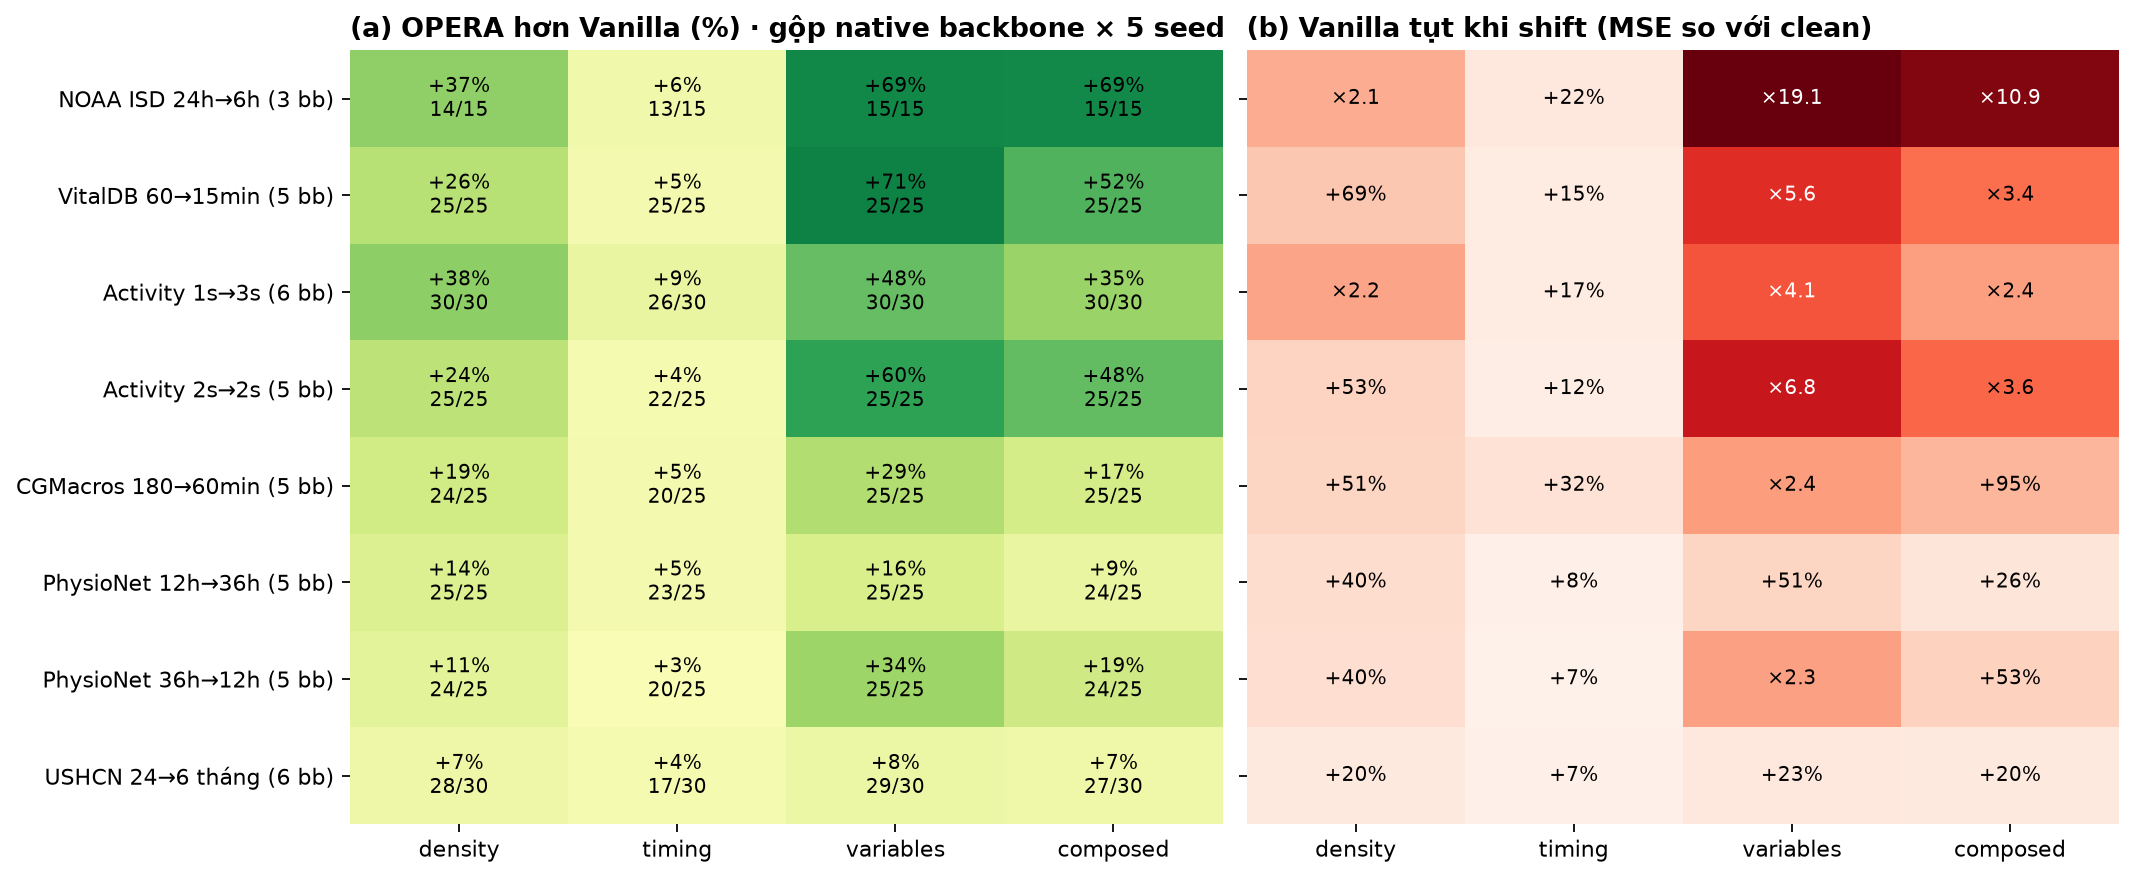

In [5]:
# (a) % OPERA hơn theo loại shift, gộp các native backbone có ở dataset đó (trung bình theo backbone × seed)
# (b) Vanilla tụt bao nhiêu % so với clean ở mỗi loại shift (cùng cách gộp)
sh = pn[pn.part.eq('shift')]
order = list(COND)
A = sh.groupby(['dataset', 'condition']).gain.mean().unstack().reindex(index=DS, columns=order)
W = sh.groupby(['dataset', 'condition']).win.agg(['sum', 'size'])
B = sh.groupby(['dataset', 'condition']).vanilla_delta.mean().unstack().reindex(index=DS, columns=order)
nbb = sh.groupby('dataset').backbone.nunique()
ylab = [f'{NAME[s]} ({nbb[s]} bb)' for s in DS]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6), sharey=True)
ax = axes[0]
ax.imshow(A.values, cmap='RdYlGn', vmin=-80, vmax=80, aspect='auto')
for i, s in enumerate(DS):
    for j, c in enumerate(order):
        w = W.loc[(s, c)]
        ax.text(j, i, f'{A.iloc[i, j]:+.0f}%\n{w["sum"]}/{w["size"]}', ha='center', va='center', fontsize=9)
ax.set_title('(a) OPERA hơn Vanilla (%) · gộp native backbone × 5 seed', loc='left', fontweight='bold')
ax = axes[1]
ax.imshow(np.log10(1 + B.values / 100), cmap='Reds', vmin=0, vmax=1.1, aspect='auto')
for i, s in enumerate(DS):
    for j, c in enumerate(order):
        v = B.iloc[i, j]
        ax.text(j, i, f'+{v:.0f}%' if v < 100 else f'×{1 + v / 100:.1f}', ha='center', va='center', fontsize=9,
                color='white' if v > 300 else 'black')
ax.set_title('(b) Vanilla tụt khi shift (MSE so với clean)', loc='left', fontweight='bold')
for ax in axes:
    ax.set_xticks(range(4), [COND[c] for c in order]); ax.set_yticks(range(len(DS)), ylab)
    for sp in ax.spines.values(): sp.set_visible(False)
fig.tight_layout()
save(fig, 'native_fig2_1_by_condition')


**Kết luận:** giống bản 3 backbone: ô nào Vanilla sụp đỏ đậm ở (b) thì xanh đậm ở (a). Cột **variables** nặng nhất ở mọi dataset trừ USHCN; cột **timing** nhạt ở cả hai bảng. Thêm t-PatchGNN/GraFITi làm VitalDB tụt mạnh hơn khi mất biến (×5.6), nên VitalDB giờ đứng thứ hai sau NOAA.

<a id="hinh-3-2"></a>

#### 📈 Hình 3.2 · Mức Vanilla sụp so với mức OPERA giúp

- Mỗi điểm = dataset × native backbone × loại shift (trung bình 5 seed). Màu = dataset; hình dạng = backbone. Trục x (cả hai panel) = MSE shift ÷ MSE clean của Vanilla, thang log.
- **(a)** trục y = % OPERA hơn Vanilla khi shift. **(b)** trục y = MSE shift ÷ MSE clean của OPERA (log). Đường nét đứt y = x là "OPERA không giúp gì"; đường ngang 1 là "không tụt chút nào".

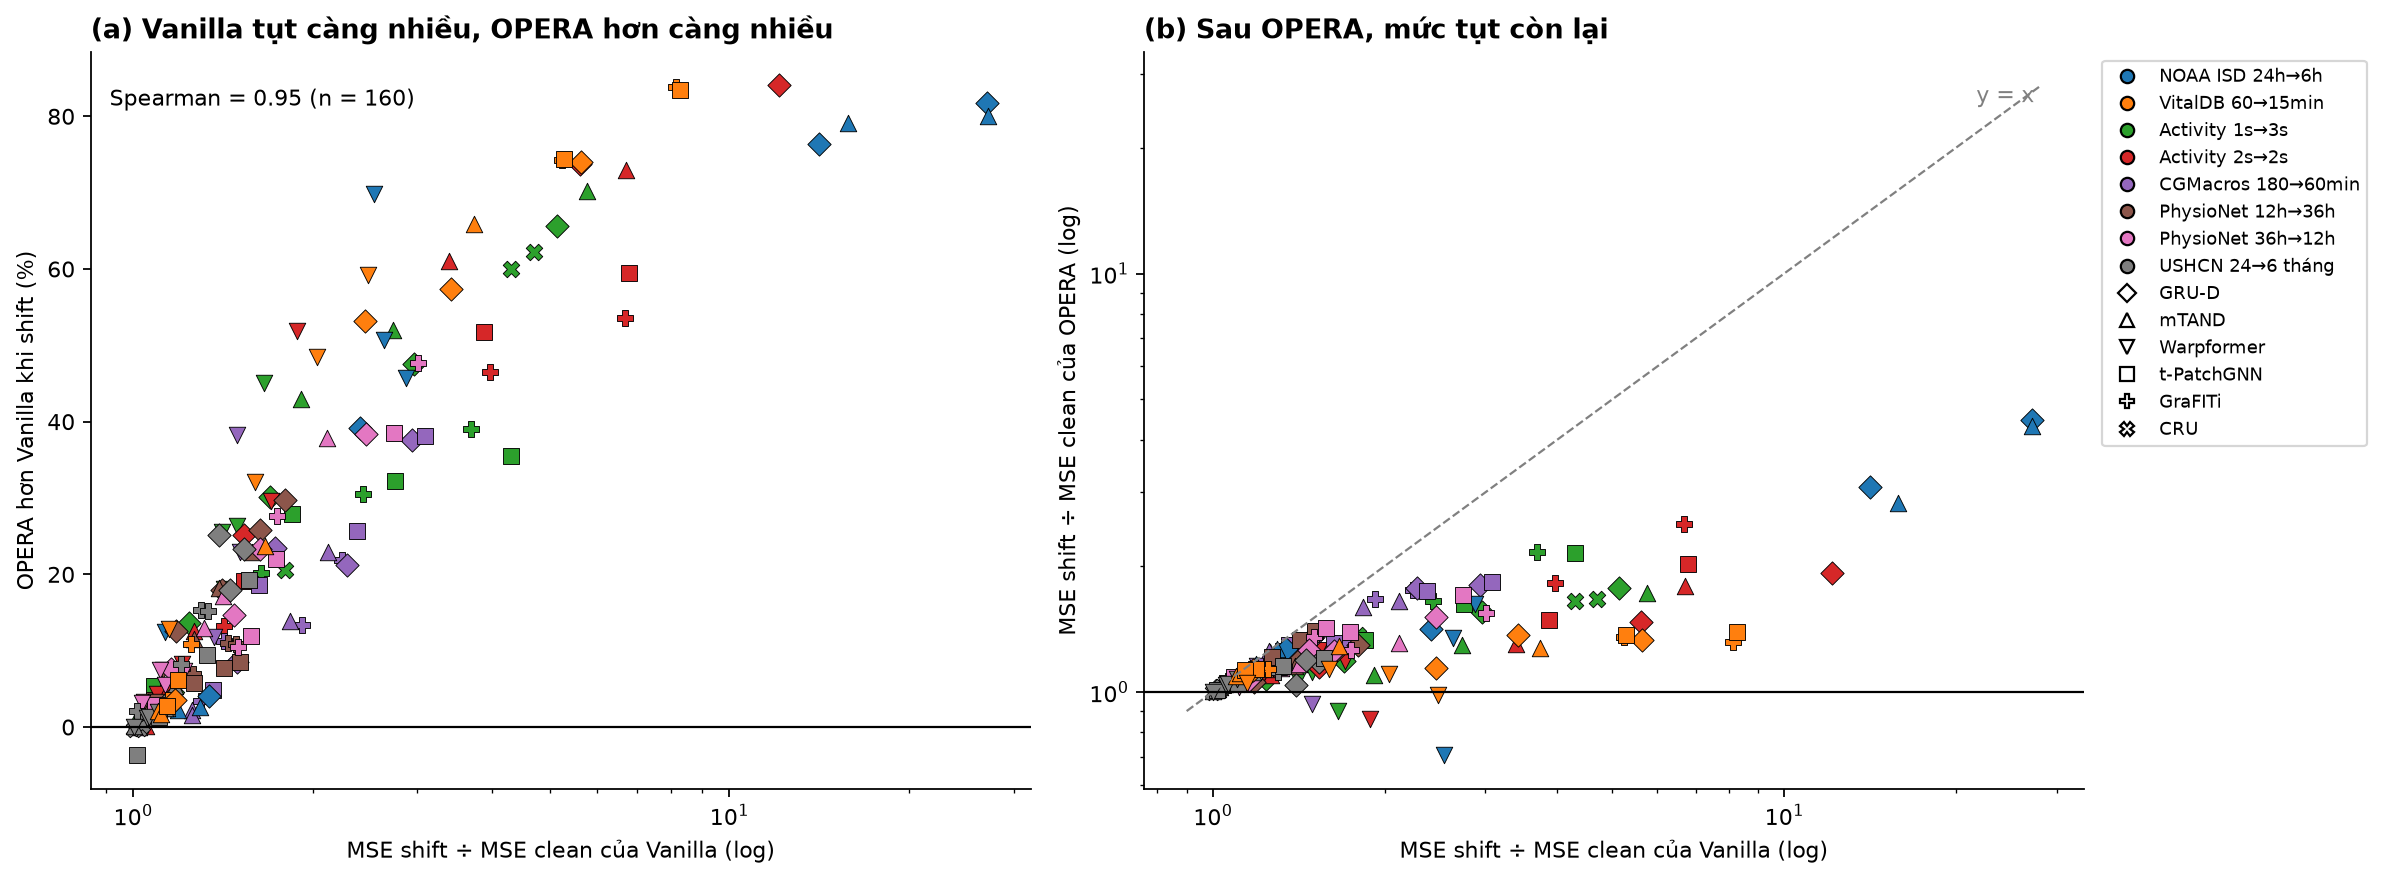

Tỉ số MSE shift/clean sau OPERA: median 1.19 · max 4.46 (NOAA ISD 24h→6h, GRU-D, variables)


In [6]:
# Mỗi điểm = dataset × native backbone × loại shift (trung bình 5 seed).
pts = pn[pn.part.eq('shift')].groupby(['dataset', 'backbone', 'condition'])[['vanilla_delta', 'gain', 'opera_delta']].mean().reset_index()
COL = dict(zip(DS, plt.cm.tab10.colors))
MK = {'grud': 'D', 'mtand': '^', 'warpformer': 'v', 'tpatchgnn': 's', 'grafiti': 'P', 'cru': 'X'}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, ycol, ttl in [(axes[0], 'gain', '(a) Vanilla tụt càng nhiều, OPERA hơn càng nhiều'),
                      (axes[1], 'opera_delta', '(b) Sau OPERA, mức tụt còn lại')]:
    for _, r in pts.iterrows():
        ax.scatter(1 + r.vanilla_delta / 100, r[ycol] if ycol == 'gain' else 1 + r[ycol] / 100,
                   marker=MK[r.backbone], s=55, color=COL[r.dataset], ec='black', lw=.4)
    ax.set_xscale('log'); ax.set_xlabel('MSE shift ÷ MSE clean của Vanilla (log)')
    ax.set_title(ttl, loc='left', fontweight='bold')
rho = spearmanr(pts.vanilla_delta, pts.gain)[0]
axes[0].axhline(0, color='black', lw=1); axes[0].set_ylabel('OPERA hơn Vanilla khi shift (%)')
axes[0].text(0.02, 0.95, f'Spearman = {rho:.2f} (n = {len(pts)})', transform=axes[0].transAxes, va='top')
axes[1].set_yscale('log'); axes[1].set_ylabel('MSE shift ÷ MSE clean của OPERA (log)')
lim = [0.9, pts.vanilla_delta.max() / 100 + 2]; axes[1].plot(lim, lim, '--', color='grey', lw=1); axes[1].text(lim[1], lim[1], 'y = x ', color='grey', va='top', ha='right')
axes[1].axhline(1, color='black', lw=1)
h = [plt.Line2D([], [], ls='', marker='o', color=COL[s], mec='black', label=NAME[s]) for s in DS]
h += [plt.Line2D([], [], ls='', marker=MK[b], color='white', mec='black', label=NATIVE[b]) for b in NATIVE]
axes[1].legend(handles=h, fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
fig.tight_layout()
save(fig, 'native_fig2_2_vanilla_drop_vs_gain')
r2 = pts.assign(r=1 + pts.opera_delta / 100)
print('Tỉ số MSE shift/clean sau OPERA: median', round(r2.r.median(), 2), '· max', round(r2.r.max(), 2),
      f'({NAME[r2.loc[r2.r.idxmax(), "dataset"]]}, {BB[r2.loc[r2.r.idxmax(), "backbone"]]}, {COND[r2.loc[r2.r.idxmax(), "condition"]]})')


**Kết luận:** (a) vẫn gần như đơn điệu (Spearman 0.95 trên 160 điểm, 6 backbone): Vanilla sụp càng nhiều thì OPERA hơn càng nhiều. (b) mọi điểm nằm dưới y = x nhưng phần lớn vẫn trên 1: OPERA giảm mức tụt chứ không xóa được. Điểm xa nhất vẫn là NOAA · GRU-D · variables (Vanilla ×27, OPERA ×4.5).

<a id="bang-3-3"></a>

#### 📋 Bảng 3.3 · Đặc điểm task cạnh kết quả, theo dataset

- **history → dự báo:** đơn vị gốc của dataset. **Cửa sổ train ≈** số batch train × batch size. **Cửa sổ test** = `n_series`.
- **Vanilla tụt / OPERA hơn:** gộp các native backbone có ở dataset đó.

In [7]:
# Đặc điểm task của từng dataset (lấy từ results.json, giống nhau giữa các run) đặt cạnh kết quả native.
info = runs.groupby('dataset')[['n_vars', 'history', 'pred_window', 'n_test', 'n_train_batches', 'batch_size']].first()
sh = pn[pn.part.eq('shift')]
summ = pd.DataFrame({
    'số biến': info.n_vars, 'history → dự báo': info.history.astype(str) + ' → ' + info.pred_window.astype(str),
    'cửa sổ train (≈)': info.n_train_batches * info.batch_size, 'cửa sổ test': info.n_test,
    'số native bb': sh.groupby('dataset').backbone.nunique(),
    'Vanilla tụt: variables': sh[sh.condition.eq('variable_dropout:0.5')].groupby('dataset').vanilla_delta.mean().map(lambda v: f'+{v:.0f}%'),
    'Vanilla tụt: timing': sh[sh.condition.eq('temporal_stride:3')].groupby('dataset').vanilla_delta.mean().map(lambda v: f'+{v:.0f}%'),
    'shift: OPERA hơn (%)': sh.groupby('dataset').gain.mean().round(1),
    'clean: OPERA hơn (%)': pn[pn.part.eq('clean')].groupby('dataset').gain.mean().round(1),
}).reindex(DS).rename(index=NAME)
display(summ)


,số biến,history → dự báo,cửa sổ train (≈),cửa sổ test,số native bb,Vanilla tụt: variables,Vanilla tụt: timing,shift: OPERA hơn (%),clean: OPERA hơn (%)
dataset,,,,,,,,,
NOAA ISD 24h→6h,5,24.0 → 6.0,14528,4531,3,+1806%,+22%,45.3,1.3
VitalDB 60→15min,11,60.0 → 15.0,9984,3232,5,+456%,+15%,38.7,2.0
Activity 1s→3s,12,1000.0 → 3000.0,1152,364,6,+311%,+17%,32.5,0.7
Activity 2s→2s,12,2000.0 → 2000.0,1696,541,5,+580%,+12%,34.2,0.5
CGMacros 180→60min,4,180.0 → 60.0,6784,2391,5,+138%,+32%,17.4,0.5
PhysioNet 12h→36h,41,12.0 → 36.0,7200,2397,5,+51%,+8%,10.9,1.5
PhysioNet 36h→12h,41,36.0 → 12.0,7200,2392,5,+131%,+7%,16.9,0.6
USHCN 24→6 tháng,5,24.0 → 6.0,2688,892,6,+23%,+7%,6.4,-0.5


**Kết luận:** số cửa sổ train hay số biến không xếp được thứ tự lợi ích. Cột xếp được là **Vanilla tụt khi mất biến** (NOAA +1806% … USHCN +23%). Clean gộp native nằm trong −0.5% đến +2.0% ở mọi dataset.

<a id="phan-4"></a>

# 4. Native và non-native: vì sao chỉ non-native mất trên clean

[↑ Tóm tắt](#summary)

<a id="hinh-4-1"></a>

#### 📈 Hình 4.1 · Vanilla nhạy với shift so với kết quả clean của OPERA

- Mỗi điểm = dataset × backbone (trung bình 5 seed). Xanh = native, đỏ = non-native. **Trục x:** MSE shift (trung bình 4 loại) ÷ MSE clean của Vanilla, thang log. **Trục y:** % OPERA hơn Vanilla khi clean (âm = OPERA kém hơn).
- Spearman tính riêng từng nhóm (trong chú thích) và gộp (trong tiêu đề). Ghi tên các điểm kém hơn 10%.

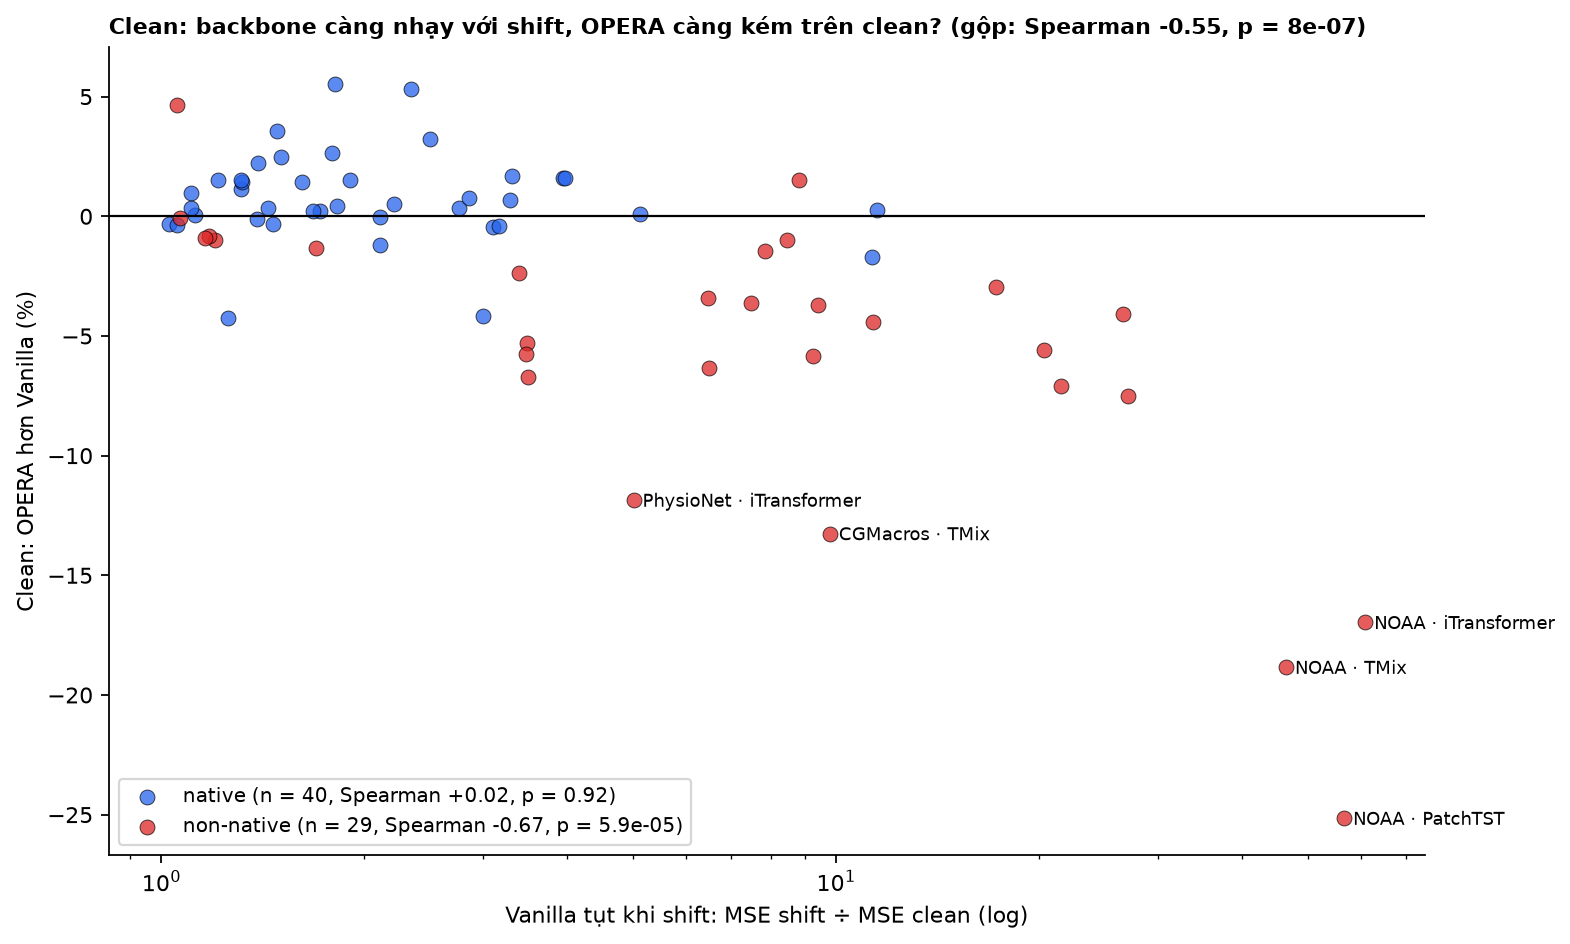

In [8]:
# Mỗi điểm = dataset × backbone (trung bình 5 seed). x = Vanilla tụt khi shift (MSE shift trung bình 4 loại ÷ MSE clean),
# y = % OPERA hơn Vanilla khi clean. Spearman tính chung và tính riêng từng nhóm.
q = pa.groupby(['family', 'dataset', 'backbone', 'part'])[['vanilla', 'opera', 'gain']].mean().unstack('part')
pp = pd.DataFrame({'sens': q[('vanilla', 'shift')] / q[('vanilla', 'clean')],
                   'clean_gain': q[('gain', 'clean')]}).reset_index()
FC = {'native': '#2563eb', 'non-native': '#dc2626'}
fig, ax = plt.subplots(figsize=(10, 6))
for fam, g in pp.groupby('family'):
    ax.scatter(g.sens, g.clean_gain, s=45, color=FC[fam], alpha=.75, ec='black', lw=.4,
               label=f'{fam} (n = {len(g)}, Spearman {spearmanr(g.sens, g.clean_gain)[0]:+.2f}, p = {spearmanr(g.sens, g.clean_gain)[1]:.2g})')
for r in pp[pp.clean_gain < -10].itertuples():
    ax.annotate(f'{NAME[r.dataset].split()[0]} · {BB[r.backbone]}', (r.sens, r.clean_gain), xytext=(4, -3), textcoords='offset points', fontsize=8)
rho_all = spearmanr(pp.sens, pp.clean_gain)
ax.axhline(0, color='black', lw=1); ax.set_xscale('log')
ax.set_xlabel('Vanilla tụt khi shift: MSE shift ÷ MSE clean (log)'); ax.set_ylabel('Clean: OPERA hơn Vanilla (%)')
ax.set_title(f'Clean: backbone càng nhạy với shift, OPERA càng kém trên clean? (gộp: Spearman {rho_all[0]:+.2f}, p = {rho_all[1]:.1g})',
             loc='left', fontweight='bold', fontsize=10)
ax.legend(loc='lower left', fontsize=9)
fig.tight_layout()
save(fig, 'native_fig4_1_sensitivity_vs_clean')


**Kết luận:** chấm xanh (native) nằm quanh 0 bất kể mức nhạy, kể cả những ô Vanilla tụt ×10. Chấm đỏ (non-native) nằm bên phải (nhạy hơn) và dưới 0, và trong nhóm đỏ thì càng nhạy càng thua nhiều. Vậy câu "nhạy với shift thì mất clean" chỉ đúng **trong nhóm non-native**. Spearman gộp −0.55 chủ yếu phản ánh khác biệt giữa hai nhóm.

<a id="bang-4-2"></a>

#### 📋 Bảng 4.2 · Các ô clean OPERA kém hơn ≥ 5%

- Kèm MSE clean tuyệt đối, và MSE clean Vanilla tốt nhất trong mọi backbone ở dataset đó, để xem ô thua có phải là model yếu sẵn hay không.

In [9]:
# Ô clean thua nặng nhất (OPERA kém hơn ≥ 5%), kèm MSE tuyệt đối để xem có phải model yếu.
c = pa[pa.part.eq('clean')].groupby(['family', 'dataset', 'backbone']).agg(gain=('gain', 'mean'), sd=('gain', 'std'), w=('win', 'sum'), n=('win', 'size'),
                                                                         V=('vanilla', 'mean'), O=('opera', 'mean')).reset_index()
best_v = pa[pa.part.eq('clean')].groupby(['dataset', 'backbone']).vanilla.mean().groupby('dataset').min()
c['MSE V tốt nhất ở dataset'] = c.dataset.map(best_v)
worst = c[c.gain <= -5].sort_values('gain')
display(pd.DataFrame({'dataset': worst.dataset.map(NAME), 'backbone': worst.backbone.map(BB), 'nhóm': worst.family,
                      'clean: OPERA hơn (%)': [f'{mark(r.w, r.n)} {r.gain:+.1f} ± {r.sd:.1f} ({r.w}/{r.n})' for r in worst.itertuples()],
                      'MSE clean V': worst.V.map('{:.4g}'.format), 'MSE clean O': worst.O.map('{:.4g}'.format),
                      'MSE clean V tốt nhất (mọi bb)': worst['MSE V tốt nhất ở dataset'].map('{:.4g}'.format)}).set_index(['dataset', 'backbone']))
print('Số ô clean OPERA kém ≥ 5%:', c[c.gain <= -5].groupby('family').size().to_dict(), '/ tổng', c.groupby('family').size().to_dict())


nhóm clean: OPERA hơn (%) MSE clean V MSE clean O MSE clean V tốt nhất (mọi bb)
dataset            backbone                                                                                           
NOAA ISD 24h→6h    PatchTST      non-native  🔴 -25.1 ± 4.8 (0/5)    0.002162    0.002706                     0.0007243
                   TMix          non-native  🔴 -18.8 ± 4.4 (0/5)    0.002276    0.002705                     0.0007243
                   iTransformer  non-native  🔴 -17.0 ± 3.6 (0/5)    0.002106    0.002463                     0.0007243
CGMacros 180→60min TMix          non-native  🔴 -13.3 ± 4.2 (0/5)    0.004315    0.004887                      0.003939
PhysioNet 36h→12h  iTransformer  non-native  🔴 -11.9 ± 5.3 (0/5)    0.004606    0.005148                      0.004227
VitalDB 60→15min   DLinear       non-native   🔴 -7.5 ± 5.9 (0/5)    0.002784    0.002993                      0.002452
Activity 2s→2s     TMix          non-native   🔴 -7.1 ± 2.3 (0/5)    0.003767    0.004034                      0.003492
PhysioNet 12h→36h  DLinear       non-native   🔴 -6.7 ± 2.4 (0/5)     0.01793     0.01913                      0.005762
PhysioNet 36h→12h  TMix          non-native   🔴 -6.3 ± 2.2 (0/5)    0.009462     0.01006                      0.004227
Activity 1s→3s     DLinear       non-native   🔴 -5.8 ± 4.8 (0/5)     0.00497    0.005263                       0.00433
PhysioNet 12h→36h  TMix          non-native   🔴 -5.7 ± 1.5 (0/5)     0.01756     0.01857                      0.005762
Activity 2s→2s     PatchTST      non-native   🔴 -5.6 ± 2.3 (0/5)    0.003795    0.004006                      0.003492
PhysioNet 12h→36h  SegRNN        non-native   🔴 -5.3 ± 1.7 (0/5)     0.01765     0.01859                      0.005762

Số ô clean OPERA kém ≥ 5%: {'non-native': 13} / tổng {'native': 40, 'non-native': 29}


**Kết luận:** cả 13 ô kém ≥ 5% đều là non-native, 0/40 ô native. Ở NOAA và PhysioNet 12h, MSE clean của Vanilla non-native đã gấp ~3 lần native tốt nhất (NOAA 0.0021–0.0023 so với 0.0007; PhysioNet 12h · DLinear/TMix/SegRNN 0.0176–0.0179 so với 0.0058), nên các ô thua nặng nhất cũng là chỗ backbone qua QuITE vốn yếu. Không dùng điều này để bỏ qua chi phí: vẫn phải báo trong paper.

<a id="phan-5"></a>

# 5. Chỗ cần cẩn thận

[↑ Tóm tắt](#summary)

<a id="bang-5-1"></a>

#### 📋 Bảng 5.1 · Run Warpformer bị NaN

- Ba run Vanilla Warpformer bị NaN giữa chừng; early stopping giữ checkpoint tốt nhất trước khi hỏng. Bảng in theo seed: epoch đã chạy, best epoch, MSE clean.
- So sánh OPERA với Vanilla khi giữ đủ 5 seed và khi bỏ seed bị NaN (bỏ cả hai phía của cặp).
- Teacher của OPERA seed k là checkpoint Vanilla seed k (`teacher_ckpt` trong `config.yaml`), nên OPERA ở các seed này cũng học từ một teacher dừng sớm.

In [10]:
# Ảnh hưởng của các run Warpformer bị NaN: so sánh có và không có các run đó (chỉ bỏ seed bị NaN ở cả hai phía cặp).
rows = []
for (s, b) in nanrun[['dataset', 'backbone']].drop_duplicates().itertuples(index=False):
    g = pa[pa.dataset.eq(s) & pa.backbone.eq(b)]
    bad = set(nanrun[nanrun.dataset.eq(s) & nanrun.backbone.eq(b)].seed)
    rv = runs[runs.dataset.eq(s) & runs.backbone.eq(b) & runs.method.eq('vanilla')].set_index('seed')
    for lab, gg in [('đủ 5 seed', g), (f'bỏ seed {sorted(bad)}', g[~g.seed.isin(bad)])]:
        c, x = gg[gg.part.eq('clean')], gg[gg.part.eq('shift')]
        rows.append({'cặp': f'{NAME[s]} · {BB[b]}', 'tập seed': lab,
                     'MSE clean V': f'{c.vanilla.mean():.4g}', 'MSE clean O': f'{c.opera.mean():.4g}',
                     'clean: OPERA hơn (%)': f'{mark(c.win.sum(), len(c))} {c.gain.mean():+.1f} ({c.win.sum()}/{len(c)})',
                     'shift: OPERA hơn (%)': f'{mark(x.win.sum(), len(x))} {x.gain.mean():+.1f} ({x.win.sum()}/{len(x)})'})
    print(f'{NAME[s]} · {BB[b]} · Vanilla: epoch chạy / best epoch / MSE clean theo seed')
    print(rv[['epochs_run', 'best_epoch', 'clean_mse', 'nan_during_training']].T.round(5).to_string(), '\n')
display(pd.DataFrame(rows).set_index(['cặp', 'tập seed']))


Activity 2s→2s · Warpformer · Vanilla: epoch chạy / best epoch / MSE clean theo seed
seed                        0        1        2         3         4
epochs_run           29.00000  40.0000  29.0000  40.00000  40.00000
best_epoch           18.00000  38.0000  18.0000  37.00000  38.00000
clean_mse             0.01173   0.0086   0.0113   0.00893   0.00892
nan_during_training   1.00000   0.0000   1.0000   0.00000   0.00000 

NOAA ISD 24h→6h · Warpformer · Vanilla: epoch chạy / best epoch / MSE clean theo seed
seed                        0         1         2        3         4
epochs_run           18.00000  27.00000  33.00000  40.0000  15.00000
best_epoch            7.00000  16.00000  22.00000  37.0000   1.00000
clean_mse             0.00329   0.00323   0.00324   0.0031   0.00428
nan_during_training   0.00000   0.00000   0.00000   0.0000   1.00000 



MSE clean V MSE clean O clean: OPERA hơn (%) shift: OPERA hơn (%)
cặp                          tập seed                                                                        
Activity 2s→2s · Warpformer  đủ 5 seed         0.009894    0.009745         ⚪ +0.4 (2/5)      🟢 +23.5 (19/20)
                             bỏ seed [0, 2]    0.008816    0.009433         🔴 -6.9 (0/3)      🟢 +23.6 (11/12)
NOAA ISD 24h→6h · Warpformer đủ 5 seed         0.003427    0.003206         🟢 +5.3 (4/5)      🟢 +44.7 (20/20)
                             bỏ seed [4]       0.003213    0.003183         ⚪ +0.9 (3/4)      🟢 +40.8 (16/16)

**Kết luận:** không đổi so với bản trước. NaN làm Vanilla dừng sớm và có MSE clean tệ hơn, nên OPERA trông như thắng khi clean. Bỏ các seed đó thì phần thắng clean mất (NOAA +0.9%) hoặc thành thua (Activity 2s→2s −6.9%, 0/3). Phần thắng shift không đổi. Muốn kết luận về Warpformer khi clean thì phải sửa lỗi NaN rồi chạy lại (`TONG_KET.md` mục 4.2).

<a id="bang-5-2"></a>

#### 📋 Bảng 5.2 · t-PatchGNN · USHCN và CRU theo seed

- % OPERA hơn Vanilla khi clean ở từng seed, và trung bình khi bỏ 2 seed tệ nhất (chỉ để xem có phải do seed lệch, không dùng làm số báo cáo).

In [11]:
# Các ô native cần để ý: t-PatchGNN · USHCN (clean), CRU (chỉ 2 dataset). In MSE clean theo seed để thấy seed lệch.
for s, b in [('ushcn_6mo', 'tpatchgnn'), ('activity_h1000', 'cru'), ('ushcn_6mo', 'cru')]:
    g = pa[pa.dataset.eq(s) & pa.backbone.eq(b) & pa.part.eq('clean')].set_index('seed')
    print(f'{NAME[s]} · {BB[b]} · clean theo seed (OPERA hơn %):', g.gain.round(1).to_dict(),
          f'· trung bình {g.gain.mean():+.1f}%, bỏ 2 seed tệ nhất {g.gain.nlargest(3).mean():+.1f}%')


USHCN 24→6 tháng · t-PatchGNN · clean theo seed (OPERA hơn %): {0: -14.1, 1: 0.2, 2: -5.9, 3: -0.4, 4: -1.0} · trung bình -4.2%, bỏ 2 seed tệ nhất -0.4%
Activity 1s→3s · CRU · clean theo seed (OPERA hơn %): {0: -4.4, 1: -2.9, 2: -3.9, 3: -6.7, 4: -2.8} · trung bình -4.1%, bỏ 2 seed tệ nhất -3.2%
USHCN 24→6 tháng · CRU · clean theo seed (OPERA hơn %): {0: -1.1, 1: 1.1, 2: -0.9, 3: -0.8, 4: 0.1} · trung bình -0.3%, bỏ 2 seed tệ nhất +0.1%


**Kết luận:** t-PatchGNN · USHCN: phần thua −4.2% chủ yếu do seed 0 (−14.1%); bỏ 2 seed tệ nhất còn −0.4%. Nên chạy thêm seed trước khi kết luận (`TONG_KET.md` mục 4.3). CRU · Activity: cả 5 seed thua 2.8–6.7%, nên đây là thua thật. CRU mới có 2 dataset và là native duy nhất có chi phí clean nhất quán. CRU · USHCN gần như không đổi ở cả clean lẫn shift.

<a id="bang-5-3"></a>

#### 📋 Bảng 5.3 · Đặt cạnh các run irregular cũ trong `results/`

- Hai lần chạy dùng commit khác nhau và không có setting nào trùng, nên **không ghép cặp** được. Chỉ so GRU-D / mTAND / Warpformer (3 backbone có ở cả hai lần).
- Mỗi ô: % OPERA hơn Vanilla, gộp 3 backbone (số cặp thắng / số cặp).

In [12]:
# Đặt kết quả native mới cạnh kết quả irregular cũ trong results/ (commit khác, setting khác, KHÔNG ghép cặp được).
old = pd.read_csv(ROOT / 'results' / 'cu_ce9a1cc' / 'per_seed_results.csv')
old = old[old.group.eq('irregular_backbone') & old.task.eq('forecast')]
op = old.pivot_table(index=['setting', 'backbone', 'seed', 'condition'], columns='method', values='mse').reset_index()
op['gain'] = 100 * (op.vanilla - op.opera) / op.vanilla; op['win'] = op.opera < op.vanilla
op['part'] = np.where(op.condition.eq('clean'), 'clean', 'shift')
def summarize(d, key):
    out = d.groupby([key, 'part']).agg(g=('gain', 'mean'), w=('win', 'sum'), n=('win', 'size')).reset_index()
    out['txt'] = [f'{mark(r.w, r.n)} {r.g:+.1f} ({r.w}/{r.n})' for r in out.itertuples()]
    return out.pivot(index=key, columns='part', values='txt')
p3 = pn[pn.backbone.isin(['grud', 'mtand', 'warpformer'])]
tbl = pd.concat([summarize(op, 'setting').assign(lần='cũ · ' + old.git_commit.iloc[0][:7]),
                 summarize(p3.rename(columns={'dataset': 'setting'}), 'setting').rename(index=NAME).assign(lần='mới · e606587')])
display(tbl.set_index('lần', append=True).rename(columns={'clean': 'clean: OPERA hơn (%)', 'shift': 'shift: OPERA hơn (%)'}))


,part,clean: OPERA hơn (%),shift: OPERA hơn (%)
setting,lần,,
activity_1000ms,cũ · ce9a1cc,⚪ +3.7 (6/15),🟢 +39.0 (56/60)
physionet_24h,cũ · ce9a1cc,⚪ +1.1 (11/15),🟢 +12.2 (57/60)
ushcn_12mo,cũ · ce9a1cc,🔴 -2.9 (1/15),⚪ -1.0 (21/60)
ushcn_1mo,cũ · ce9a1cc,⚪ +0.5 (11/15),🟢 +4.8 (58/60)
Activity 1s→3s,mới · e606587,⚪ +1.6 (9/15),🟢 +36.5 (58/60)
Activity 2s→2s,mới · e606587,⚪ +0.0 (6/15),🟢 +36.0 (57/60)
CGMacros 180→60min,mới · e606587,⚪ +0.8 (7/15),🟢 +17.5 (56/60)
NOAA ISD 24h→6h,mới · e606587,⚪ +1.3 (10/15),🟢 +45.3 (57/60)
PhysioNet 12h→36h,mới · e606587,🟢 +1.6 (12/15),🟢 +13.4 (57/60)


**Kết luận:** xu hướng giống nhau: shift thắng lớn ở Activity, vừa ở PhysioNet, nhỏ ở USHCN; clean gần hòa. Lần chạy cũ có một chỗ thua rõ là USHCN 12 tháng (clean −2.9%, shift −1.0%). Lần mới không chạy USHCN 12 tháng nên chưa biết lỗi đó còn không.